In [2]:
import os
import importlib

from pymetropsis.plotting import plot_metropsis_timeseries, plot_metropsis_group

#os.chdir("..")

ImportError: 

IMPORTANT: PLEASE READ THIS FOR ADVICE ON HOW TO SOLVE THIS ISSUE!

Importing the numpy C-extensions failed. This error can happen for
many reasons, often due to issues with your setup or how NumPy was
installed.

We have compiled some common reasons and troubleshooting tips at:

    https://numpy.org/devdocs/user/troubleshooting-importerror.html

Please note and check the following:

  * The Python version is: Python3.10 from "/Users/hheinrichs/mambaforge/envs/civibe/bin/python"
  * The NumPy version is: "1.24.2"

and make sure that they are the versions you expect.
Please carefully study the documentation linked above for further help.

Original error was: dlopen(/Users/hheinrichs/mambaforge/envs/civibe/lib/python3.10/site-packages/numpy/core/_multiarray_umath.cpython-310-darwin.so, 0x0002): Library not loaded: @rpath/libgfortran.5.dylib
  Referenced from: <C435405B-BFF1-399F-A1EC-BD43418F546A> /Users/hheinrichs/mambaforge/envs/civibe/lib/libopenblas.0.dylib
  Reason: 

Figure saved to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/reports/fig/tcs/fig_psychophysics_test_timeseries_212-2.pdf


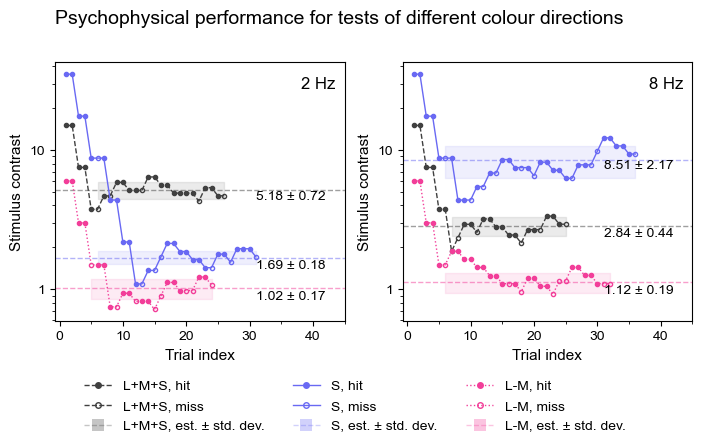

In [3]:
importlib.reload(plot_metropsis_timeseries)
plot_metropsis_timeseries.main()

In [ ]:
from pymetropsis.plotting.plot_metropsis_group import (
    create_plot_blocks_group_timecourses,
    DATA_DIR,
    PROJECT_ROOT,
)

from pymetropsis.plotting.plot_metropsis_group import (
    summarize_contrastsens_by,
)

from pymetropsis.plotting.plot_utils import save_figure
import pandas as pd
from pathlib import Path    


data_path = DATA_DIR / "raw/clean_metropsis_TCS-2e.csv"
meldata_path = DATA_DIR / "raw/clean_saliva_data.csv"
melstat_path = DATA_DIR / "derivatives/hormones/tau_harmonics/melatonin_circadian_parameters.csv"
out_dir = PROJECT_ROOT / "reports/fig"  # "/Users/hheinrichs/Downloads"

# Create output directories
out_dir = Path(out_dir)

# Load data
data = pd.read_csv(data_path)

# Get and merge melatonin data and melatonin circadian statistiics
melraw = pd.read_csv(meldata_path)
melstat = pd.read_csv(melstat_path)
meldata = melraw.merge(melstat, on="participant_id")

# Summarize data across participants
pid_df = summarize_contrastsens_by(
    data=data, group_vars=["participant_id", "block", "condition", "freq"]
)
pid_df.sort_values(by=["participant_id", "condition", "freq", "block"])
median_participant = pid_df["participant_id"].median()  # 206

# Create average plots
fig, _ = create_plot_blocks_group_timecourses(data=pid_df)
fig.set_figheight(4)
fig.set_figwidth(7)
display(fig)
save_figure(fig_dir=out_dir / "tcs", fig_name="img_metropsis_blocks_group.pdf", fig=fig)

Figure saved to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/reports/fig/tcs/img_metropsis_blocks_group.pdf


/var/folders/7y/65rqw3j92j350_5qs3b9cdjm0002fv/T/ipykernel_62352/3545885883.py:43: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()
